# Health Insurance Claims Fraud Detection using Supervised Learning

Target: `Is_Fraud` (0 = legitimate, 1 = fraud). Stratified train/test split; every preprocessing step lives inside a pipeline, so it is fitted on training data only (and re-fitted on the training part of each CV fold).

Two choices are crossed for every model where the combination is technically possible:
- **Missing values:** *impute* (median / mode) or *no-impute* (NaN kept; a missing category becomes its own one-hot level)
- **Imbalance:** *SMOTE* (SMOTENC) or *class weights* (`class_weight` / `scale_pos_weight`)

| Model | impute + SMOTE | impute + weight | no-impute + weight | no-impute + SMOTE |
|---|---|---|---|---|
| Logistic Regression (untuned) | yes | yes | no: needs imputed data | no |
| KNN (tuned) | yes | no: KNN has no class weights | no: needs imputed data | no |
| Decision Tree (tuned) | yes | yes | yes | no: SMOTENC cannot take NaN |
| Random Forest (tuned) | yes | yes | yes | no |
| XGBoost (tuned) | yes | yes | yes | no |

That is 12 models. Tuned models share one hyper-parameter grid per algorithm, **3-fold stratified CV**, the same scoring (trapezoidal AUC-PR) and the same search budget.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## 1. Load Data

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nudratabbas/healthcare-fraud-detection-dataset")
print("Path to dataset files:", path)

100%|██████████| 281k/281k [00:00<00:00, 416kB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/nudratabbas/healthcare-fraud-detection-dataset/versions/1


In [3]:
import os

# Locate the CSV file inside the downloaded dataset folder
csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
csv_path = os.path.join(path, csv_file)
print("Reading:", csv_path)

df = pd.read_csv(csv_path)
df.head(2)

Reading: /root/.cache/kagglehub/datasets/nudratabbas/healthcare-fraud-detection-dataset/versions/1/healthcare_fraud_detection.csv


,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0


In [4]:
df['Claim_ID'].nunique()

10000

In [5]:
df['Provider_ID'].nunique()

300

Provider_ID is a high-cardinality identifier. Encoding it would blow up the feature space and let the model memorise individual providers rather than learn general fraud patterns, which wouldn’t generalise to new providers.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Provider_ID                            10000 non-null  object 
 1   Claim_ID                               10000 non-null  object 
 2   Patient_Age                            10000 non-null  int64  
 3   Patient_Gender                         10000 non-null  object 
 4   Diagnosis_Code                         10000 non-null  object 
 5   Procedure_Code                         10000 non-null  int64  
 6   Claim_Amount                           10000 non-null  float64
 7   Approved_Amount                        10000 non-null  float64
 8   Insurance_Type                         9650 non-null   object 
 9   Claim_Submission_Date                  10000 non-null  object 
 10  Days_Between_Service_and_Claim         10000 non-null  int64  
 11  Num

In [7]:
df.describe()

,Patient_Age,Procedure_Code,Claim_Amount,Approved_Amount,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Is_Fraud,Length_of_Stay,Chronic_Condition_Flag,Prior_Visits_12m
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,9650.000000
mean,49.755000,86905.21170,572.804406,475.514157,14.413800,68.628000,0.082900,2.19930,0.292000,3.026425
std,17.910144,14965.32496,406.202437,323.257165,8.489875,14.905872,0.275745,1.71046,0.454705,1.722789
min,1.000000,36415.00000,60.210000,50.350000,0.000000,42.000000,0.000000,0.00000,0.000000,0.000000
25%,37.750000,80053.00000,305.205000,257.200000,7.000000,60.000000,0.000000,1.00000,0.000000,2.000000
50%,50.000000,93000.00000,461.225000,388.370000,14.000000,66.000000,0.000000,2.00000,0.000000,3.000000
75%,62.000000,99213.00000,711.365000,598.347500,22.000000,72.000000,0.000000,3.00000,1.000000,4.000000
max,95.000000,99214.00000,6590.700000,4270.890000,29.000000,144.000000,1.000000,5.00000,1.000000,12.000000


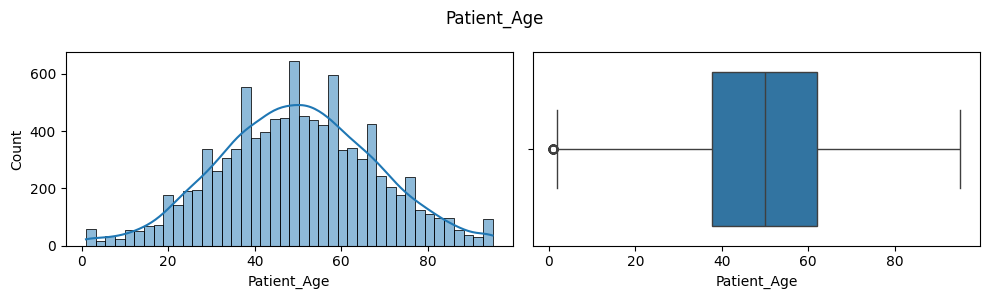

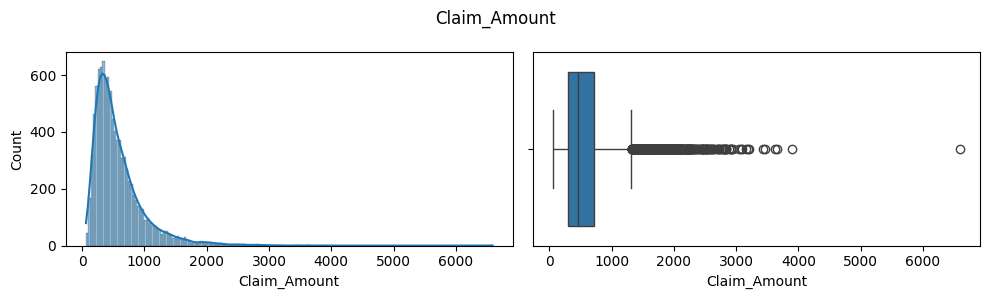

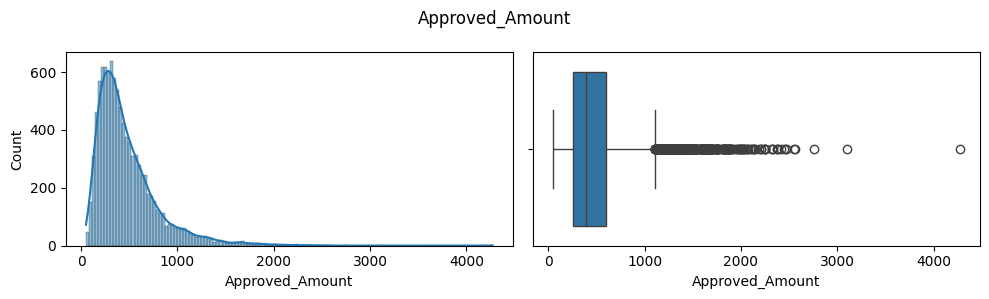

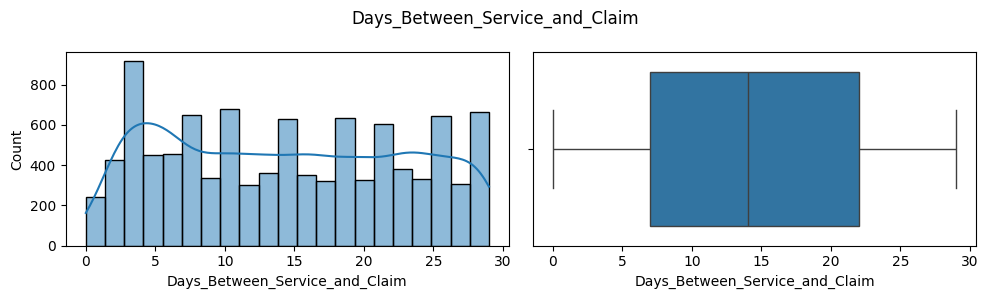

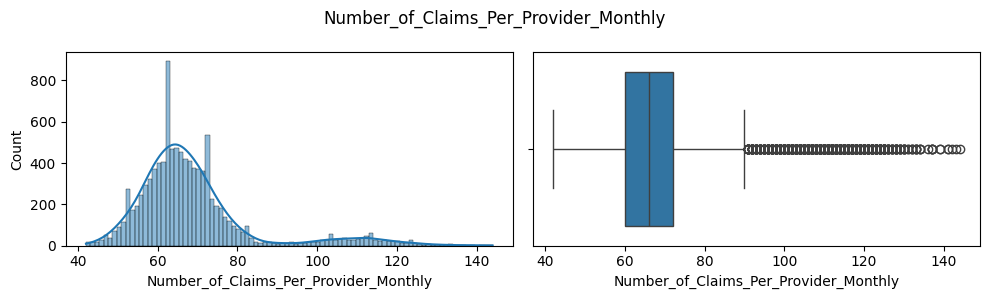

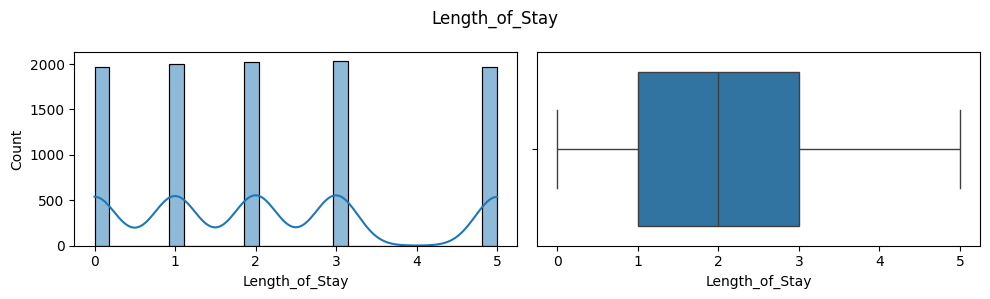

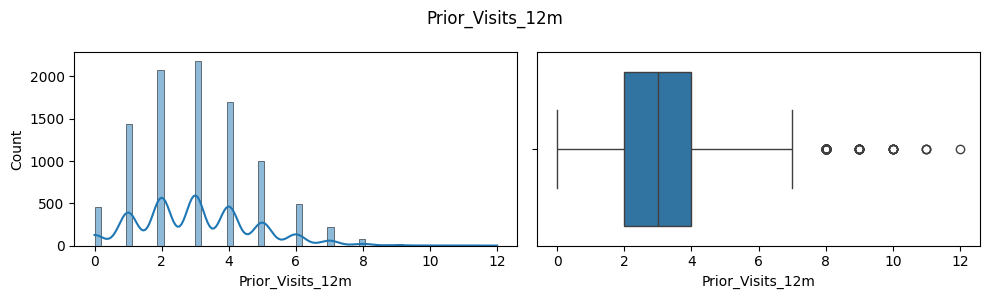

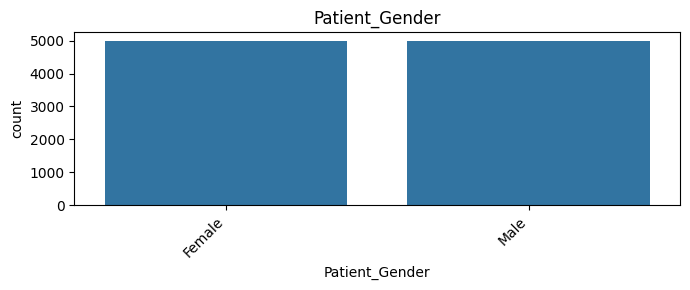

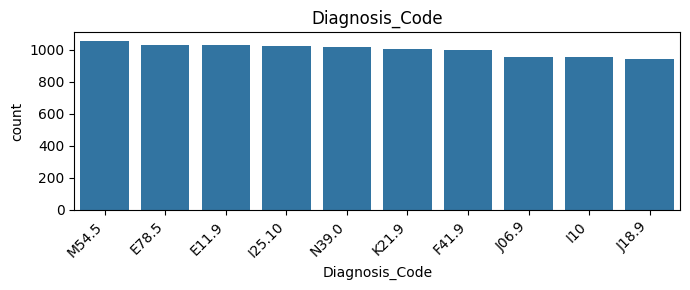

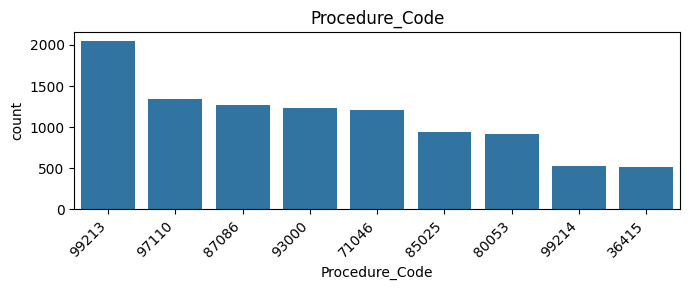

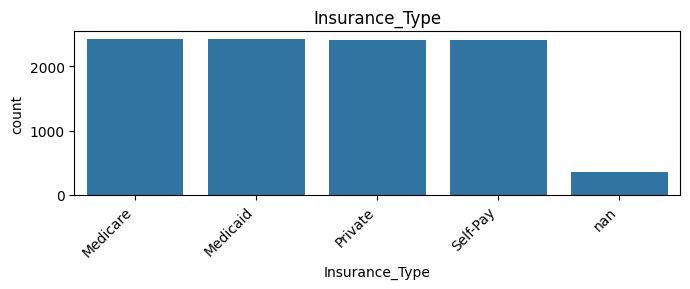

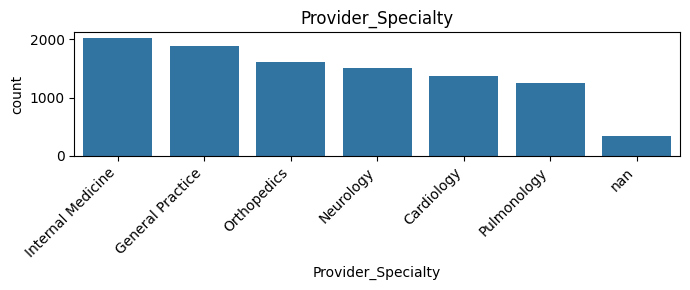

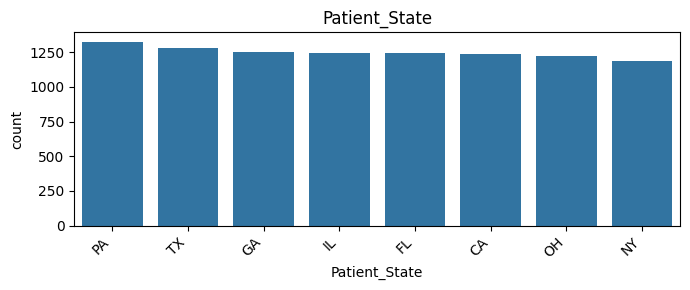

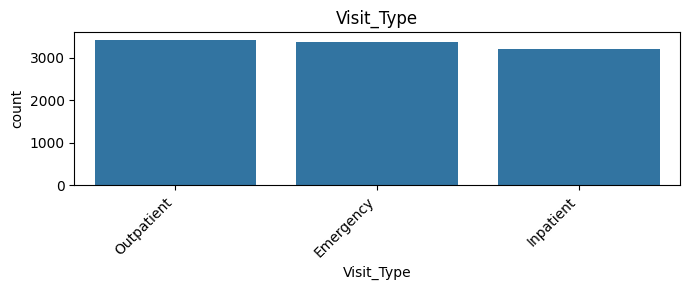

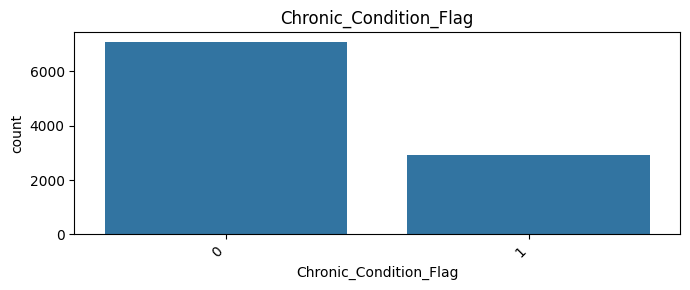

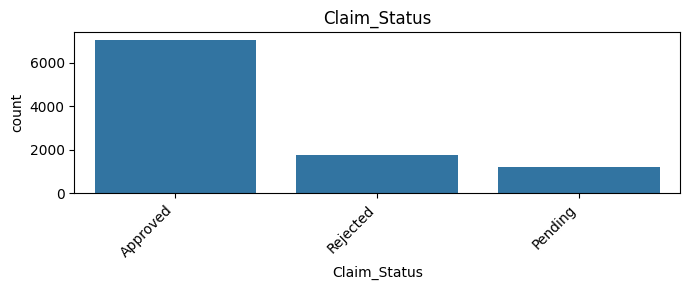

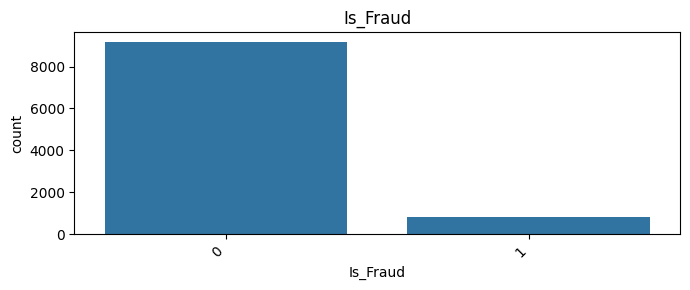

In [8]:
skip     = ['Claim_ID', 'Provider_ID', 'Claim_Submission_Date']        # identifiers and raw date
cat_cols = ['Patient_Gender', 'Diagnosis_Code', 'Procedure_Code', 'Insurance_Type', 'Provider_Specialty',
            'Patient_State', 'Visit_Type', 'Chronic_Condition_Flag', 'Claim_Status', 'Is_Fraud']
num_cols = [c for c in df.columns if c not in skip + cat_cols]

# Numeric columns: histogram (shape) + boxplot (outliers)
for c in num_cols:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    sns.histplot(df[c].dropna(), kde=True, ax=ax[0])
    sns.boxplot(x=df[c], ax=ax[1])
    fig.suptitle(c); plt.tight_layout(); plt.show()

# Categorical columns: bar chart of counts (top 15 levels; missing shows as 'nan')
for c in cat_cols:
    s = df[c].astype(str)
    plt.figure(figsize=(7, 3))
    sns.countplot(x=s, order=s.value_counts().index[:15])
    plt.title(c); plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

In [9]:
df.shape

(10000, 20)

## 2. Missing Values

In [10]:
##Checking for Missing Observations
df.isnull().sum()

,0
Provider_ID,0
Claim_ID,0
Patient_Age,0
Patient_Gender,0
Diagnosis_Code,0
Procedure_Code,0
Claim_Amount,0
Approved_Amount,0
Insurance_Type,350
Claim_Submission_Date,0


In [11]:
#Checking Missing Values
features=[i for i in df.columns if df[i].isnull().sum()>=1]
for j in features:
    print(j,np.round(df[j].isnull().mean()*100,5),'% missing values')

Insurance_Type 3.5 % missing values
Provider_Specialty 3.5 % missing values
Prior_Visits_12m 3.5 % missing values


**No imputation is done here.** The missing values are deliberately left in the data. Imputation statistics (median / mode) are learned inside the modelling pipelines, from training data only, and inside each CV fold whenever cross-validation is used. Doing it on the full dataframe (or on the full training set before CV) would let validation rows influence the values used to fill training rows.

## 3. Feature Engineering
`Claim_Submission_Date` is a raw date string; we extract a `Claim_Submission_Month` feature from it (to capture any seasonality) and drop the original date column. `Procedure_Code` is numeric but represents a small set of discrete billing codes (CPT-style), so we cast it to a categorical/string type so it gets one-hot encoded rather than scaled.

In [12]:
#Feature engineering from the claim submission date
df['Claim_Submission_Date'] = pd.to_datetime(df['Claim_Submission_Date'])
df['Claim_Submission_Month'] = df['Claim_Submission_Date'].dt.month

#Removing insignificant Features (unique identifiers with no predictive value)
df.drop(['Claim_ID','Provider_ID','Claim_Submission_Date'],axis=1,inplace=True)

#Procedure_Code is a discrete billing code, not a continuous numeric quantity -> treat as categorical
#(astype(str) alone would turn a NaN into the string 'nan', i.e. a hidden imputation, so only cast observed values)
_pc = df['Procedure_Code']
df['Procedure_Code'] = _pc.astype(str).where(_pc.notna(), np.nan)

In [13]:
## get all the numeric features
num_features = [feature for feature in df.columns if df[feature].dtype != 'O']

num_features = [col for col in num_features if col not in ['Chronic_Condition_Flag', 'Claim_Submission_Month', 'Number_of_Claims_Per_Provider_Monthly']]
num_features
num_features1 = num_features.copy()
num_features1.remove('Is_Fraud')

print('Number of Numerical Features :', len(num_features1))
num_features1

Number of Numerical Features : 6


['Patient_Age',
 'Claim_Amount',
 'Approved_Amount',
 'Days_Between_Service_and_Claim',
 'Length_of_Stay',
 'Prior_Visits_12m']

In [14]:
# Get all the categorical features
cat_features = ['Patient_Gender', 'Diagnosis_Code', 'Procedure_Code', 'Insurance_Type', 'Provider_Specialty', 'Patient_State', 'Visit_Type', 'Chronic_Condition_Flag', 'Claim_Submission_Month']
print('Num of Categorical Features :', len(cat_features))
cat_features

Num of Categorical Features : 9


['Patient_Gender',
 'Diagnosis_Code',
 'Procedure_Code',
 'Insurance_Type',
 'Provider_Specialty',
 'Patient_State',
 'Visit_Type',
 'Chronic_Condition_Flag',
 'Claim_Submission_Month']

Claim_Status and Approved_Amount should be excluded because the information might not be available while prediction.
This project is suitable for post-adjudication audit tool.

In [15]:
##Discrete Features
disc_feat=[features for features in num_features if len(df[features].unique())<=25 ]
print(len(disc_feat))

3


In [16]:
##Continuous Features
cont_feat=[features for features in num_features if features not in disc_feat ]
print(len(cont_feat))

4


In [17]:
df.shape

(10000, 18)

## 4. Machine Learning

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import (roc_auc_score, recall_score, f1_score, precision_score,
                             accuracy_score, precision_recall_curve, auc, make_scorer)

RANDOM_STATE = 42
TEST_SIZE    = 0.20

def pr_auc(y_true, y_score):
    """Area under the precision-recall curve (trapezoidal rule over all thresholds)."""
    precision, recall, _ = precision_recall_curve(y_true, y_score)
    return auc(recall, precision)

SCORING = make_scorer(pr_auc, response_method="predict_proba")   # used by every CV / search (needs scikit-learn >= 1.4)
N_ITER       = 16

In [19]:

FEATURES = cat_features + num_features1          # categorical columns first (needed for SMOTENC indices)

X, y = df[FEATURES], df['Is_Fraud']
x_train_raw, x_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)   # STRATIFIED, before any preprocessing

print('Train:', x_train_raw.shape, '| Test:', x_test_raw.shape)
print(f'Fraud rate  train: {y_train.mean():.4f} | test: {y_test.mean():.4f}')


Train: (8000, 15) | Test: (2000, 15)
Fraud rate  train: 0.0829 | test: 0.0830


### Pipelines

- Impute rows (LR, KNN, and the impute rows of DT, RF, XGBoost): impute (median / mode), then ordinal-encode and scale, then optional SMOTENC, then one-hot, then model.
- No-impute rows (DT, RF, XGBoost): categoricals are one-hot encoded with a missing level of their own, and numeric NaNs pass through for the models to handle natively.

Imputation statistics are learned from training data only: from each fold's training part inside CV, and from the full training set for the final fit. The test set only receives those training statistics.

In [20]:
cat_idx = list(range(len(cat_features)))
SPW = float((y_train == 0).sum() / (y_train == 1).sum())     # negatives / positives, from TRAIN labels only

def make_ordinal_prep():                      # impute -> ordinal-encode / scale
    cat_pipe = SkPipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))])
    num_pipe = SkPipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    return ColumnTransformer([("cat", cat_pipe, cat_features), ("num", num_pipe, num_features1)], sparse_threshold=0)

def make_onehot_post():                       # one-hot AFTER (optional) SMOTENC
    return ColumnTransformer([("ohe", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_idx)],
                             remainder="passthrough", sparse_threshold=0)

def make_native_prep():                       # NO imputation: one-hot categoricals (NaN = own level), numeric NaN kept
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
                              ("num", "passthrough", num_features1)], sparse_threshold=0)

def impute_smote(model):
    return ImbPipeline([("prep", make_ordinal_prep()),
                        ("smote", SMOTENC(categorical_features=cat_idx, random_state=RANDOM_STATE)),
                        ("onehot", make_onehot_post()), ("model", model)])

def impute_weight(model):
    return ImbPipeline([("prep", make_ordinal_prep()), ("onehot", make_onehot_post()), ("model", model)])

def noimpute_weight(model):
    return ImbPipeline([("prep", make_native_prep()), ("model", model)])

# Base models; the flag w switches on class weighting (n_jobs=1 inside, searches parallelise over folds)
MODELS = {
    "LR":  lambda w: LogisticRegression(max_iter=2000, class_weight="balanced" if w else None),
    "KNN": lambda w: KNeighborsClassifier(),                       # no class_weight option
    "DT":  lambda w: DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced" if w else None),
    "RF":  lambda w: RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1, class_weight="balanced" if w else None),
    "XGB": lambda w: XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1,
                                   scale_pos_weight=SPW if w else 1.0),
}

PARAMS = {   # one grid per algorithm, reused by every combination of that algorithm
    "LR":  None,                                                    # untuned
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11, 15, 20, 25], "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
    "DT":  {"model__criterion": ["gini", "entropy"], "model__max_depth": [3, 5, 7, 10, 15, None],
            "model__min_samples_split": [2, 5, 10, 20, 50], "model__min_samples_leaf": [1, 2, 5, 10, 20],
            "model__max_features": [None, "sqrt", 0.5]},
    "RF":  {"model__max_depth": [5, 8, 10, 15, None], "model__max_features": [0.3, 0.5, 0.7, "sqrt"],
            "model__min_samples_split": [2, 8, 15, 20], "model__n_estimators": [100, 200, 300, 500]},
    "XGB": {"model__n_estimators": [100, 200, 500, 1000], "model__max_depth": [3, 5, 7, 10],
            "model__learning_rate": [0.01, 0.05, 0.1, 0.2], "model__subsample": [0.7, 0.8, 1.0],
            "model__colsample_bytree": [0.7, 0.8, 1.0]},
}

# Every technically valid (missing-value handling, imbalance handling) combination per model
COMBOS = {
    "LR":  [("impute", "SMOTE"), ("impute", "weight")],
    "KNN": [("impute", "SMOTE")],
    "DT":  [("impute", "SMOTE"), ("impute", "weight"), ("no-impute", "weight")],
    "RF":  [("impute", "SMOTE"), ("impute", "weight"), ("no-impute", "weight")],
    "XGB": [("impute", "SMOTE"), ("impute", "weight"), ("no-impute", "weight")],
}

def build(name, missing, imb):
    assert not (missing == "no-impute" and imb == "SMOTE"), "SMOTENC cannot handle NaN"
    model = MODELS[name](imb == "weight")
    if missing == "no-impute": return noimpute_weight(model)
    return impute_smote(model) if imb == "SMOTE" else impute_weight(model)

REGISTRY = {}   # label -> (pipeline, grid, meta)
for name, combos in COMBOS.items():
    for missing, imb in combos:
        REGISTRY[f"{name} | {missing}+{imb}"] = (build(name, missing, imb), PARAMS[name],
                                                 {"Algorithm": name, "Missing": missing, "Imbalance": imb,
                                                  "Tuned": PARAMS[name] is not None})
print(len(REGISTRY), "models:", list(REGISTRY))

# Sanity check: the no-impute models must still see NaNs in the numeric columns
_chk = make_native_prep().fit_transform(x_train_raw)
print("NaNs reaching the no-impute models:", int(np.isnan(_chk).sum()), "| feature matrix:", _chk.shape)

12 models: ['LR | impute+SMOTE', 'LR | impute+weight', 'KNN | impute+SMOTE', 'DT | impute+SMOTE', 'DT | impute+weight', 'DT | no-impute+weight', 'RF | impute+SMOTE', 'RF | impute+weight', 'RF | no-impute+weight', 'XGB | impute+SMOTE', 'XGB | impute+weight', 'XGB | no-impute+weight']
NaNs reaching the no-impute models: 281 | feature matrix: (8000, 64)


## Fit and tune

**3-fold** stratified CV, one metric (trapezoidal **AUC-PR**: area under the precision-recall curve) and one search budget for every tuned model. Searches run on the **raw** training data, so imputation and SMOTENC are re-fitted inside each fold. The untuned Logistic Regression models get CV scores from the same folds, so every row of the final table has a comparable CV number and per-fold scores are paired across models.

In [21]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

fitted, cv_scores, cv_folds = {}, {}, {}
for label, (pipe, grid, meta) in REGISTRY.items():
    print(f"Fitting {label} ...")
    if grid is None:
        folds = cross_val_score(pipe, x_train_raw, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
        fitted[label] = pipe.fit(x_train_raw, y_train)
    else:
        search = RandomizedSearchCV(pipe, grid, n_iter=N_ITER, scoring=SCORING, cv=cv,
                                    n_jobs=-1, random_state=RANDOM_STATE, refit=True)
        search.fit(x_train_raw, y_train)
        folds = np.array([search.cv_results_[f"split{k}_test_score"][search.best_index_] for k in range(cv.get_n_splits())])
        fitted[label] = search.best_estimator_
        print(f"   best params: {search.best_params_}")
    cv_folds[label] = np.asarray(folds)
    cv_scores[label] = (np.mean(folds), np.std(folds))
    print(f"   CV AUC-PR = {cv_scores[label][0]:.4f} ± {cv_scores[label][1]:.4f}")

Fitting LR | impute+SMOTE ...
   CV AUC-PR = 0.9784 ± 0.0058
Fitting LR | impute+weight ...
   CV AUC-PR = 0.9748 ± 0.0054
Fitting KNN | impute+SMOTE ...
   best params: {'model__weights': 'uniform', 'model__p': 2, 'model__n_neighbors': 25}
   CV AUC-PR = 0.5795 ± 0.0256
Fitting DT | impute+SMOTE ...
   best params: {'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': None, 'model__criterion': 'entropy'}
   CV AUC-PR = 0.9171 ± 0.0194
Fitting DT | impute+weight ...
   best params: {'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': None, 'model__criterion': 'entropy'}
   CV AUC-PR = 0.9194 ± 0.0073
Fitting DT | no-impute+weight ...
   best params: {'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': None, 'model__max_depth': None, 'model__criterion': 'entropy'}
   CV AUC-PR = 0.9141 ± 0.0084
Fitting RF | impute+SMOTE ...
   best params:

## Test-set performance and comparison

Every model is scored on the same untouched test set; the pipelines receive the raw test data and apply training statistics internally. Precision / recall / F1 use the default 0.5 cut-off, which is **not comparable** between SMOTE and class-weight models (their probabilities are calibrated differently), so compare models on the threshold-free **AUC-PR**.

In [22]:
rows = []
for label, model in fitted.items():
    proba = model.predict_proba(x_test_raw)[:, 1]
    pred = (proba >= 0.5).astype(int)
    meta = REGISTRY[label][2]
    rows.append({"Model": label, "Missing": meta["Missing"], "Imbalance": meta["Imbalance"],
                 "Tuned": "yes" if meta["Tuned"] else "no",
                 "CV AUC-PR": cv_scores[label][0], "CV std": cv_scores[label][1],
                 "Test AUC-PR": pr_auc(y_test, proba),
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0),
                 "Accuracy": accuracy_score(y_test, pred)})

comparison_df = pd.DataFrame(rows).sort_values("CV AUC-PR", ascending=False).reset_index(drop=True)
print(f"Random-guess AUC-PR baseline (test fraud rate): {y_test.mean():.4f}")
comparison_df.round(4)

Random-guess AUC-PR baseline (test fraud rate): 0.0830


,Model,Missing,Imbalance,Tuned,CV AUC-PR,CV std,Test AUC-PR,ROC-AUC,Precision,Recall,F1,Accuracy
0,XGB | impute+SMOTE,impute,SMOTE,yes,0.9830,0.0024,0.9866,0.9984,0.9080,0.9518,0.9294,0.9880
1,XGB | no-impute+weight,no-impute,weight,yes,0.9809,0.0030,0.9802,0.9975,0.9281,0.9337,0.9309,0.9885
2,XGB | impute+weight,impute,weight,yes,0.9806,0.0032,0.9800,0.9975,0.9118,0.9337,0.9226,0.9870
3,LR | impute+SMOTE,impute,SMOTE,no,0.9784,0.0058,0.9785,0.9976,0.8368,0.9578,0.8933,0.9810
4,LR | impute+weight,impute,weight,no,0.9748,0.0054,0.9764,0.9972,0.7443,0.9819,0.8468,0.9705
5,RF | no-impute+weight,no-impute,weight,yes,0.9736,0.0041,0.9792,0.9975,0.9434,0.9036,0.9231,0.9875
6,RF | impute+weight,impute,weight,yes,0.9733,0.0048,0.9794,0.9974,0.9554,0.9036,0.9288,0.9885
7,RF | impute+SMOTE,impute,SMOTE,yes,0.9684,0.0002,0.9761,0.9974,0.8619,0.9398,0.8991,0.9825
8,DT | impute+weight,impute,weight,yes,0.9194,0.0073,0.9166,0.9457,0.8613,0.8976,0.8791,0.9795
9,DT | impute+SMOTE,impute,SMOTE,yes,0.9171,0.0194,0.9402,0.9778,0.8377,0.9639,0.8964,0.9815


## Effect of each choice (paired by CV fold)

Because the combinations are crossed, two rows of the same algorithm that differ in **one** factor isolate that factor:
- *SMOTE vs class weights*: `impute+SMOTE` minus `impute+weight` (missing-value handling held fixed)
- *Impute vs native NaN*: `no-impute+weight` minus `impute+weight` (imbalance handling held fixed)

The difference is computed on the same 3 folds. With only 3 folds the spread is a rough guide: a gain smaller than its spread is **within noise**, not evidence of an effect. Hyper-parameters were tuned separately per row, so this compares tuned configurations.

In [23]:
def paired(a, b):
    d = cv_folds[a] - cv_folds[b]
    return d.mean(), d.std(ddof=1)

eff = []
for m in ["LR", "DT", "RF", "XGB"]:
    g, sd = paired(f"{m} | impute+SMOTE", f"{m} | impute+weight")
    eff.append({"Algorithm": m, "Question": "SMOTE minus class weights (impute)", "Mean gain": g, "Spread": sd,
                "Verdict": "within noise" if abs(g) < sd else ("SMOTE better" if g > 0 else "weights better")})
for m in ["DT", "RF", "XGB"]:
    g, sd = paired(f"{m} | no-impute+weight", f"{m} | impute+weight")
    eff.append({"Algorithm": m, "Question": "native NaN minus impute (weights)", "Mean gain": g, "Spread": sd,
                "Verdict": "within noise" if abs(g) < sd else ("native NaN better" if g > 0 else "imputation better")})
pd.DataFrame(eff).round(4)

,Algorithm,Question,Mean gain,Spread,Verdict
0,LR,SMOTE minus class weights (impute),0.0036,0.0021,SMOTE better
1,DT,SMOTE minus class weights (impute),-0.0023,0.0266,within noise
2,RF,SMOTE minus class weights (impute),-0.0049,0.0056,within noise
3,XGB,SMOTE minus class weights (impute),0.0024,0.0016,SMOTE better
4,DT,native NaN minus impute (weights),-0.0053,0.0025,imputation better
5,RF,native NaN minus impute (weights),0.0003,0.0023,within noise
6,XGB,native NaN minus impute (weights),0.0003,0.0006,within noise
